<a href="https://colab.research.google.com/github/chulsoo3060/YOLO_SEJONG/blob/main/YOLO_3Models_Cross_Dataset_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip -q install ultralytics pyyaml

from pathlib import Path
import zipfile
import shutil
import yaml
import torch
import pandas as pd
import matplotlib.pyplot as plt

from ultralytics import YOLO
from google.colab import files, drive
from IPython.display import display

print("GPU 사용 가능:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("Colab에서 T4 GPU를 활성화하세요.")

print("GPU:", torch.cuda.get_device_name(0))

# 학습 모델과 그래프 영구 보관
drive.mount("/content/drive")

SAVE_DIR = Path(
    "/content/drive/MyDrive/YOLO_3Models_Comparison"
)

SAVE_DIR.mkdir(parents=True, exist_ok=True)

print("결과 저장 폴더:", SAVE_DIR)

GPU 사용 가능: True
GPU: Tesla T4
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
결과 저장 폴더: /content/drive/MyDrive/YOLO_3Models_Comparison


In [4]:
print("세 데이터셋 ZIP 파일을 모두 선택하세요.")

uploaded = files.upload()

print("업로드:", list(uploaded.keys()))

def find_uploaded(prefix):
    matches = [
        name for name in uploaded
        if name.lower().startswith(prefix.lower())
        and name.lower().endswith(".zip")
    ]

    if len(matches) != 1:
        raise FileNotFoundError(
            f"{prefix} ZIP 파일 확인 필요: {matches}"
        )

    return Path("/content") / matches[0]

zip_files = {
    "mine": find_uploaded("my-bottle-detection"),
    "sanghyeon": find_uploaded("Yolo.v1i"),
    "jian": find_uploaded("Bottle Detection"),
}

print(zip_files)

세 데이터셋 ZIP 파일을 모두 선택하세요.


Saving Bottle Detection.v1-my_bottle-70-20-10.yolov11.zip to Bottle Detection.v1-my_bottle-70-20-10.yolov11.zip
Saving my-bottle-detection.v1i.yolov11.zip to my-bottle-detection.v1i.yolov11.zip
Saving Yolo.v1i.yolov11.zip to Yolo.v1i.yolov11.zip
업로드: ['Bottle Detection.v1-my_bottle-70-20-10.yolov11.zip', 'my-bottle-detection.v1i.yolov11.zip', 'Yolo.v1i.yolov11.zip']
{'mine': PosixPath('/content/my-bottle-detection.v1i.yolov11.zip'), 'sanghyeon': PosixPath('/content/Yolo.v1i.yolov11.zip'), 'jian': PosixPath('/content/Bottle Detection.v1-my_bottle-70-20-10.yolov11.zip')}


In [5]:
DATA_ROOT = Path("/content/yolo_3_datasets")

ORDER = ["mine", "sanghyeon", "jian"]

DISPLAY_NAMES = {
    "mine": "Mine model",
    "sanghyeon": "Sanghyeon model",
    "jian": "Jian model"
}

DATA_NAMES = {
    "mine": "Mine Test",
    "sanghyeon": "Sanghyeon Test",
    "jian": "Jian Test"
}

data_yamls = {}

for person in ORDER:

    dest = DATA_ROOT / person

    if dest.exists():
        shutil.rmtree(dest)

    dest.mkdir(parents=True)

    with zipfile.ZipFile(zip_files[person]) as zf:
        zf.extractall(dest)

    yaml_path = dest / "data.yaml"

    if not yaml_path.exists():
        raise FileNotFoundError(
            f"{person}: data.yaml 없음"
        )

    with open(yaml_path, encoding="utf-8") as f:
        config = yaml.safe_load(f)

    config.update({
        "path": str(dest),
        "train": "train/images",
        "val": "valid/images",
        "test": "test/images"
    })

    if config.get("names") != ["my_bottle"]:
        raise ValueError(
            f"클래스 확인 필요: {config.get('names')}"
        )

    for split in ["train", "val", "test"]:
        if not (dest / config[split]).is_dir():
            raise FileNotFoundError(
                f"{person}: {split} 폴더 없음"
            )

    with open(yaml_path, "w", encoding="utf-8") as f:
        yaml.safe_dump(
            config,
            f,
            allow_unicode=True,
            sort_keys=False
        )

    data_yamls[person] = str(yaml_path)

    counts = {
        split: len(
            list((dest / split / "images").glob("*.jpg"))
        )
        for split in ["train", "valid", "test"]
    }

    print(person, counts)

print("3개 데이터셋 준비 완료")

mine {'train': 141, 'valid': 40, 'test': 20}
sanghyeon {'train': 155, 'valid': 31, 'test': 15}
jian {'train': 141, 'valid': 40, 'test': 20}
3개 데이터셋 준비 완료


In [6]:
RUN_ROOT = Path("/content/yolo_train_runs")

weights = {}

for person in ORDER:

    print(f"\n===== {person} 학습 시작 =====")

    # 매번 같은 사전학습 모델에서 출발
    model = YOLO("yolo11n.pt")

    model.train(
        data=data_yamls[person],
        epochs=50,
        imgsz=640,
        batch=16,
        device=0,
        seed=42,
        deterministic=True,
        workers=2,
        project=str(RUN_ROOT),
        name=person,
        exist_ok=True,
        plots=True
    )

    best_file = (
        RUN_ROOT / person / "weights" / "best.pt"
    )

    if not best_file.exists():
        raise FileNotFoundError(best_file)

    saved_weight = SAVE_DIR / f"best_{person}.pt"

    shutil.copy2(best_file, saved_weight)

    weights[person] = str(saved_weight)

    print("저장 완료:", saved_weight)

print("\n모든 모델 학습 완료")
print(weights)


===== mine 학습 시작 =====
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_3_datasets/mine/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=mine, nbs=64, nms=None, o

In [7]:
weights = {
    person: str(SAVE_DIR / f"best_{person}.pt")
    for person in ORDER
}

for path in weights.values():
    if not Path(path).exists():
        raise FileNotFoundError(path)

records = []

for model_name in ORDER:

    model = YOLO(weights[model_name])

    for test_name in ORDER:

        print(
            f"\n{model_name} 모델 → {test_name} Test"
        )

        metrics = model.val(
            data=data_yamls[test_name],
            split="test",
            imgsz=640,
            batch=1,
            device=0,
            workers=2,
            plots=False,
            verbose=False,
            project="/content/yolo_cross_eval",
            name=f"{model_name}_on_{test_name}",
            exist_ok=True
        )

        records.append({
            "model": model_name,
            "test_dataset": test_name,
            "Precision": float(metrics.box.mp),
            "Recall": float(metrics.box.mr),
            "mAP50": float(metrics.box.map50),
            "mAP50-95": float(metrics.box.map),
            "Inference_ms": float(
                metrics.speed["inference"]
            )
        })

        pd.DataFrame(records).to_csv(
            SAVE_DIR / "cross_dataset_results_partial.csv",
            index=False
        )

results_df = pd.DataFrame(records)

results_df.to_csv(
    SAVE_DIR / "cross_dataset_results.csv",
    index=False
)

print("총 평가 횟수:", len(results_df))

display(results_df.round(4))


mine 모델 → mine Test
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 16.8±6.3 MB/s, size: 28.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/yolo_3_datasets/mine/test/labels... 20 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20/20 567.2it/s 0.0s
val: New cache created: /content/yolo_3_datasets/mine/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 20/20 36.5it/s 0.5s
                   all         20         20      0.997          1      0.995      0.899
Speed: 1.4ms preprocess, 14.6ms inference, 0.0ms loss, 1.2ms postprocess per image

mine 모델 → sanghyeon Test
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2

,model,test_dataset,Precision,Recall,mAP50,mAP50-95,Inference_ms
0,mine,mine,0.9966,1.0000,0.9950,0.8988,14.6410
1,mine,sanghyeon,0.7179,0.2000,0.1879,0.1079,14.4415
2,mine,jian,0.0093,0.1000,0.0009,0.0003,12.7501
3,sanghyeon,mine,0.2561,0.3500,0.1626,0.0584,13.2006
4,sanghyeon,sanghyeon,0.9967,1.0000,0.9950,0.8359,13.8178
5,sanghyeon,jian,0.4822,0.4000,0.4096,0.2111,14.2819
6,jian,mine,0.0136,0.2000,0.0031,0.0007,19.8146
7,jian,sanghyeon,0.2937,0.4000,0.1289,0.0522,17.9969
8,jian,jian,1.0000,0.9856,0.9950,0.8031,19.2926


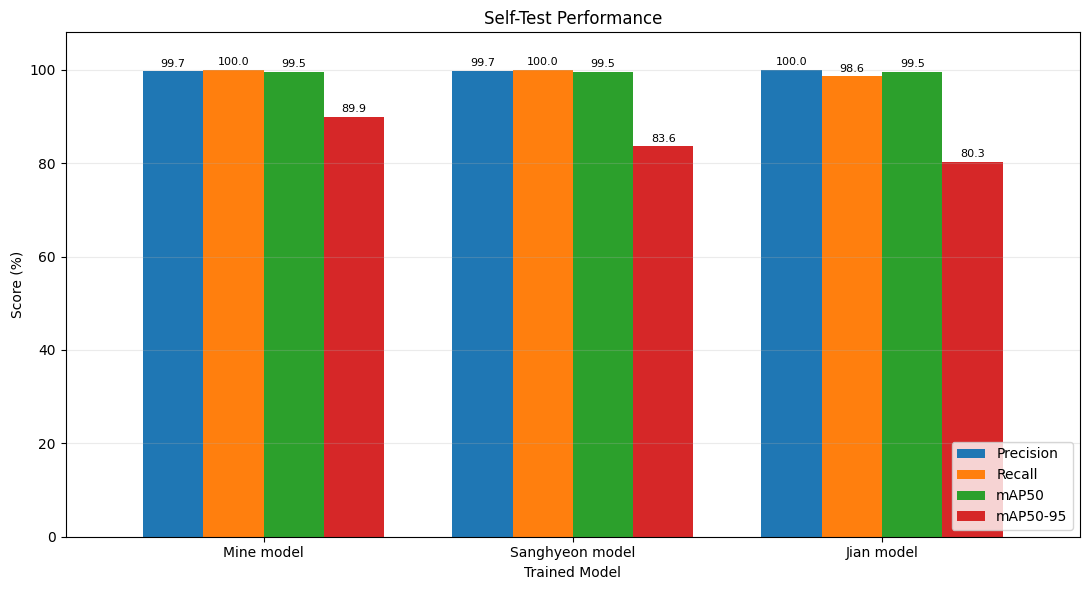

In [8]:
metric_cols = [
    "Precision",
    "Recall",
    "mAP50",
    "mAP50-95"
]

self_df = results_df[
    results_df["model"] == results_df["test_dataset"]
].copy()

self_df = (
    self_df
    .set_index("model")
    .loc[ORDER, metric_cols] * 100
)

self_df.index = [
    DISPLAY_NAMES[x] for x in self_df.index
]

ax = self_df.plot(
    kind="bar",
    figsize=(11, 6),
    rot=0,
    width=0.78
)

ax.set_title("Self-Test Performance")
ax.set_xlabel("Trained Model")
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 108)
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="lower right")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f",
        padding=2,
        fontsize=8
    )

plt.tight_layout()

plt.savefig(
    SAVE_DIR / "self_test_performance.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()

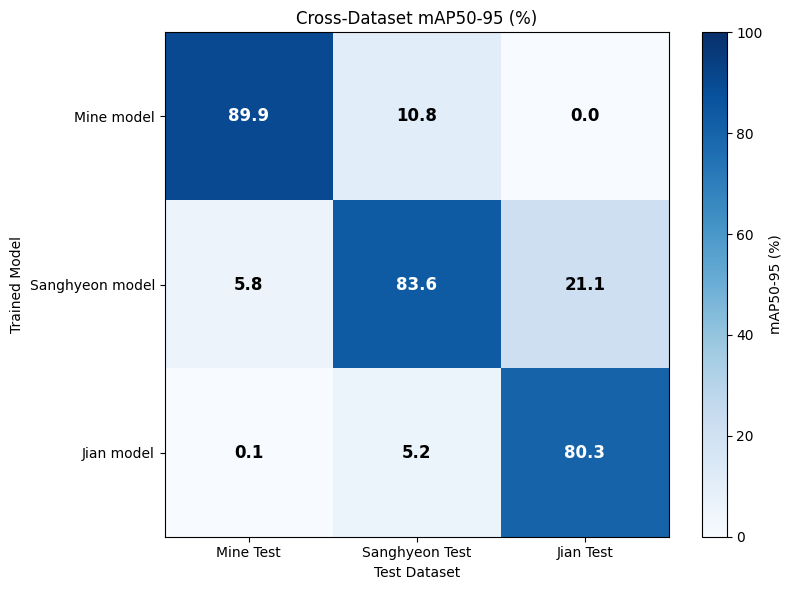

In [9]:
mat = results_df.pivot(
    index="model",
    columns="test_dataset",
    values="mAP50-95"
)

mat = mat.reindex(
    index=ORDER,
    columns=ORDER
) * 100

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(
    mat.values,
    cmap="Blues",
    vmin=0,
    vmax=100
)

ax.set_xticks(
    range(3),
    [DATA_NAMES[x] for x in ORDER]
)

ax.set_yticks(
    range(3),
    [DISPLAY_NAMES[x] for x in ORDER]
)

ax.set_xlabel("Test Dataset")
ax.set_ylabel("Trained Model")
ax.set_title("Cross-Dataset mAP50-95 (%)")

for row in range(3):
    for col in range(3):

        value = mat.iat[row, col]

        ax.text(
            col,
            row,
            f"{value:.1f}",
            ha="center",
            va="center",
            color="white" if value >= 55 else "black",
            fontsize=12,
            fontweight="bold"
        )

fig.colorbar(
    im,
    ax=ax,
    label="mAP50-95 (%)"
)

plt.tight_layout()

plt.savefig(
    SAVE_DIR / "cross_dataset_heatmap.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()

In [10]:
package = Path(
    "/content/YOLO_3Models_Comparison_Results.zip"
)

file_names = [
    "cross_dataset_results.csv",
    "self_test_performance.png",
    "cross_dataset_heatmap.png",
    "best_mine.pt",
    "best_sanghyeon.pt",
    "best_jian.pt"
]

with zipfile.ZipFile(
    package,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zf:

    for filename in file_names:

        path = SAVE_DIR / filename

        if not path.exists():
            raise FileNotFoundError(path)

        zf.write(
            path,
            arcname=filename
        )

print("완료:", package)

files.download(str(package))

완료: /content/YOLO_3Models_Comparison_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>